<a href="https://colab.research.google.com/github/irfanizzath/Personal-Notebooks/blob/main/HuggingFace.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

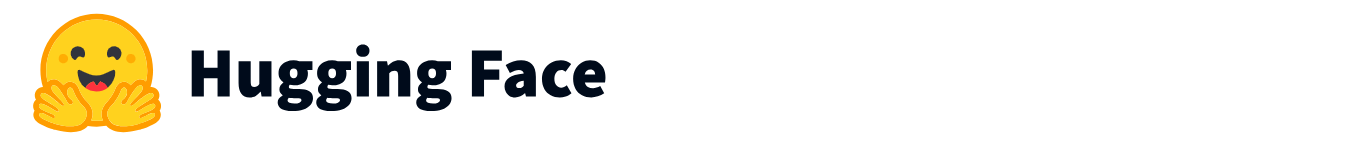

In [ ]:
!pip install -U transformers datasets

# **K2 Horizon by MBZUAI**

## Local Inference on GPU
Model page: https://huggingface.co/IFM/K2-Horizon-0.9B

⚠️ If the generated code snippets do not work, please open an issue on either the [model repo](https://huggingface.co/IFM/K2-Horizon-0.9B)
			and/or on [huggingface.js](https://github.com/huggingface/huggingface.js/blob/main/packages/tasks/src/model-libraries-snippets.ts) 🙏

In [ ]:
# Use a pipeline as a high-level helper
from transformers import pipeline

pipe = pipeline("text-generation", model="IFM/K2-Horizon-0.9B", trust_remote_code=True)
messages = [
    {"role": "user", "content": "What's the capital of the UAE?"},
]
pipe(messages)


Loading weights:   0%|          | 0/255 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': [{'role': 'user',
    'content': "What's the capital of the UAE?"},
   {'role': 'assistant',
    'content': 'The user asks: "What\'s the capital of the UAE?" That\'s a straightforward factual query.@article? Actually it\'s "What\'s the capital of the UAE?" The answer: Abu Dhabi is the capital of the United Arab Emirates (UAE). However, there is also Dubai as the capital of the United Arab Emirates? Actually the UAE comprises the United Arab Emirates (UAE) and the State of Qatar. The capital of the United Arab Emirates (UAE) is Abu Dhabi. The capital of the UAE is Abu Dhabi. The Kingdom of Saudi Arabia? Wait no, the capital of the United Arab Emirates is Abu Dhabi. Also, the capital of the Arab Emirates is Abu Dhabi. So answer: Abu Dhabi.\n\nBut perhaps the user might want more context. The question: "What\'s the capital of the UAE?" The answer: Abu Dhabi. Provide a concise answer.\n\nThus answer: Abu Dhabi.\n\n</ifm|think>\nThe capital of the United Arab Emirates (U

# **Tokenization**

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from datasets import load_dataset


# Load datasets
train_data = load_dataset(
    "stanfordnlp/imdb",
    split="train"
).shard(num_shards=4, index=0)

test_data = load_dataset(
    "stanfordnlp/imdb",
    split="test"
).shard(num_shards=4, index=0)

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(
    "bert-base-uncased"
)

# Tokenization function
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=128
    )

# Tokenize datasets
tokenized_training_data = train_data.map(
    tokenize_function,
    batched=True
)

tokenized_test_data = test_data.map(
    tokenize_function,
    batched=True
)

# Load model
model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
print(tokenized_training_data)

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 6250
})
